# IND320 Assignment 2

## Collecting data from Magasinstatistikk API

In [1]:
import requests
import pandas as pd

URL_MAGASIN = "https://biapi.nve.no/magasinstatistikk/api/Magasinstatistikk/HentOffentligData"

response = requests.get(URL_MAGASIN, timeout = 15)

df = pd.DataFrame(response.json())

In [2]:
# Translating the name of the columns to English and renaming them in the dataframe
df.columns = ['Date', 'area_type','area_nr', 'iso_year', 'iso_week', 
              'res_level', 'capacity_TWh', 'res_level_TWh', 
              'next_publish_date', 'prev_res_level', 'change_res_level']

# Sorting the dataframe by date in ascending order
df = df.sort_values(by=['Date'], ascending=False)
df['Date'] = pd.to_datetime(df['Date'])

# Displaying the data types of each column in the dataframe
# print(df.dtypes)

# Rounding all float columns to 2 decimal places
float_cols = df.select_dtypes("float").columns
df[float_cols] = df[float_cols].round(2)

# Displaying the first 5 rows of the dataframe sorted by date
print(df.head().to_string())

           Date area_type  area_nr  iso_year  iso_week  res_level  capacity_TWh  res_level_TWh    next_publish_date  prev_res_level  change_res_level
8283 2026-10-11        EL        3      2026        41       0.73          8.92           6.47  2026-10-21T13:00:00            0.72              0.01
8284 2026-10-11        EL        1      2026        41       0.75          6.00           4.49  2026-10-21T13:00:00            0.75             -0.00
8286 2026-10-11        EL        4      2026        41       0.91         21.08          19.17  2026-10-21T13:00:00            0.89              0.02
8288 2026-10-11        EL        2      2026        41       0.52         34.04          17.75  2026-10-21T13:00:00            0.51              0.01
8289 2026-10-11        EL        5      2026        41       0.72         17.39          12.60  2026-10-21T13:00:00            0.71              0.02


### Weekly reservoirs levels (%) in NO over time

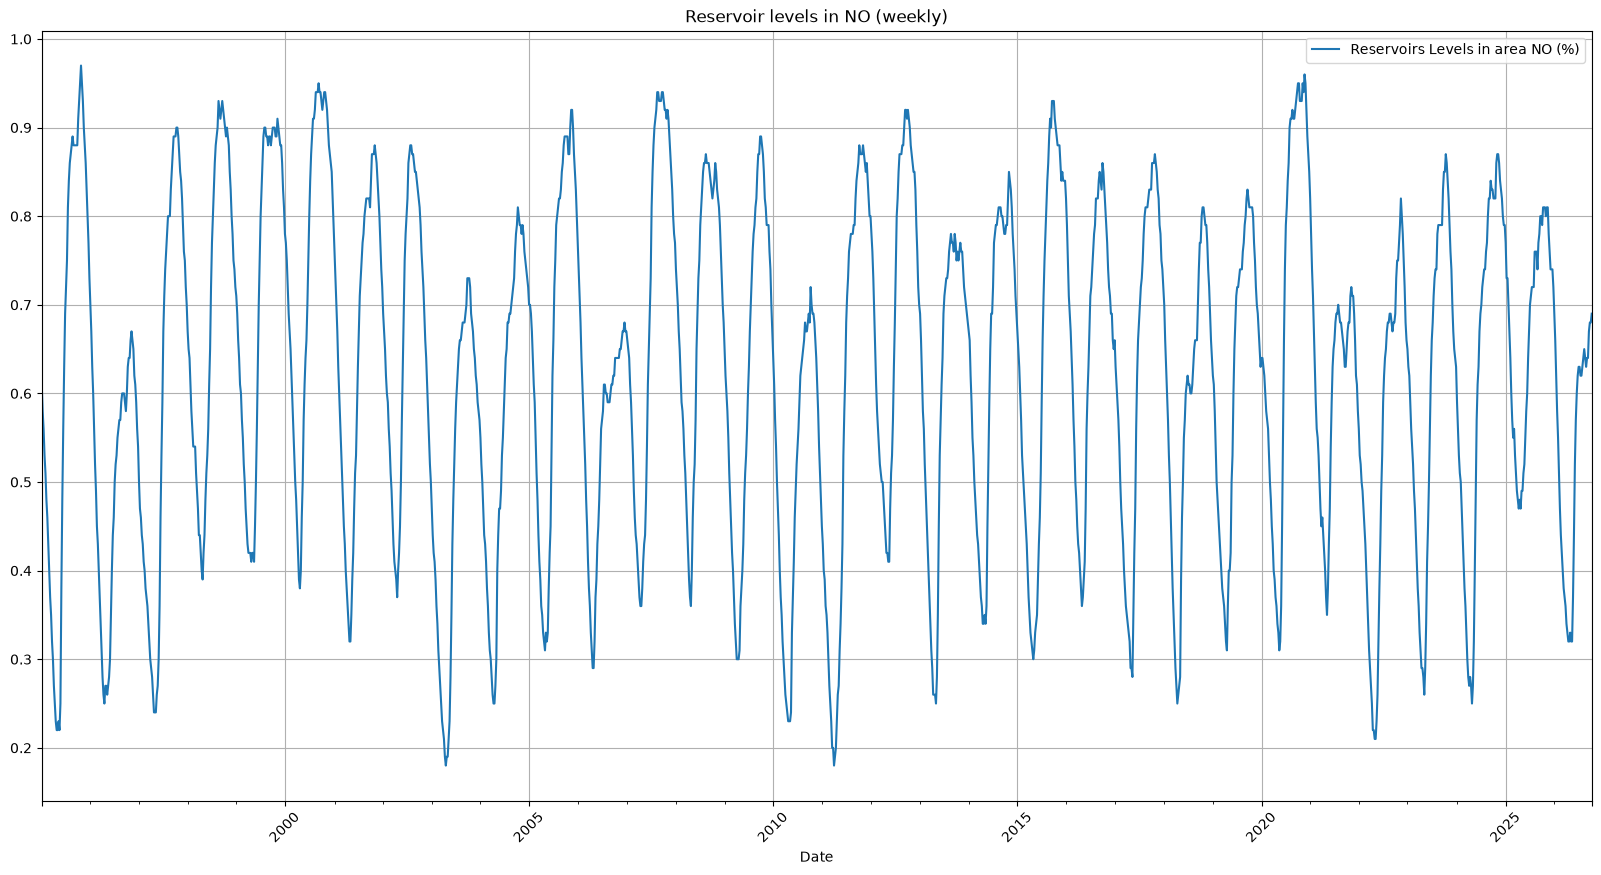

In [3]:
#importing matplolib.pyplot for plotting
import matplotlib.pyplot as plt

# Plotting the reservoir levels in NO over time
subset_1 = df[df['area_type'] == 'NO']

# Plotting reservoir levels in area type NO
ax1 = subset_1.plot(x='Date', 
              y='res_level', 
              kind='line', 
              title='Reservoir levels in NO (weekly)', 
              figsize=(20,10),
              rot=45, 
              grid=True)

# Renaming the legend to be easier to understand
ax1.legend(['Reservoirs Levels in area NO (%)'])

# Making sure the plot is shown
plt.show()

### Reservoirs levels in TWh in area type NO

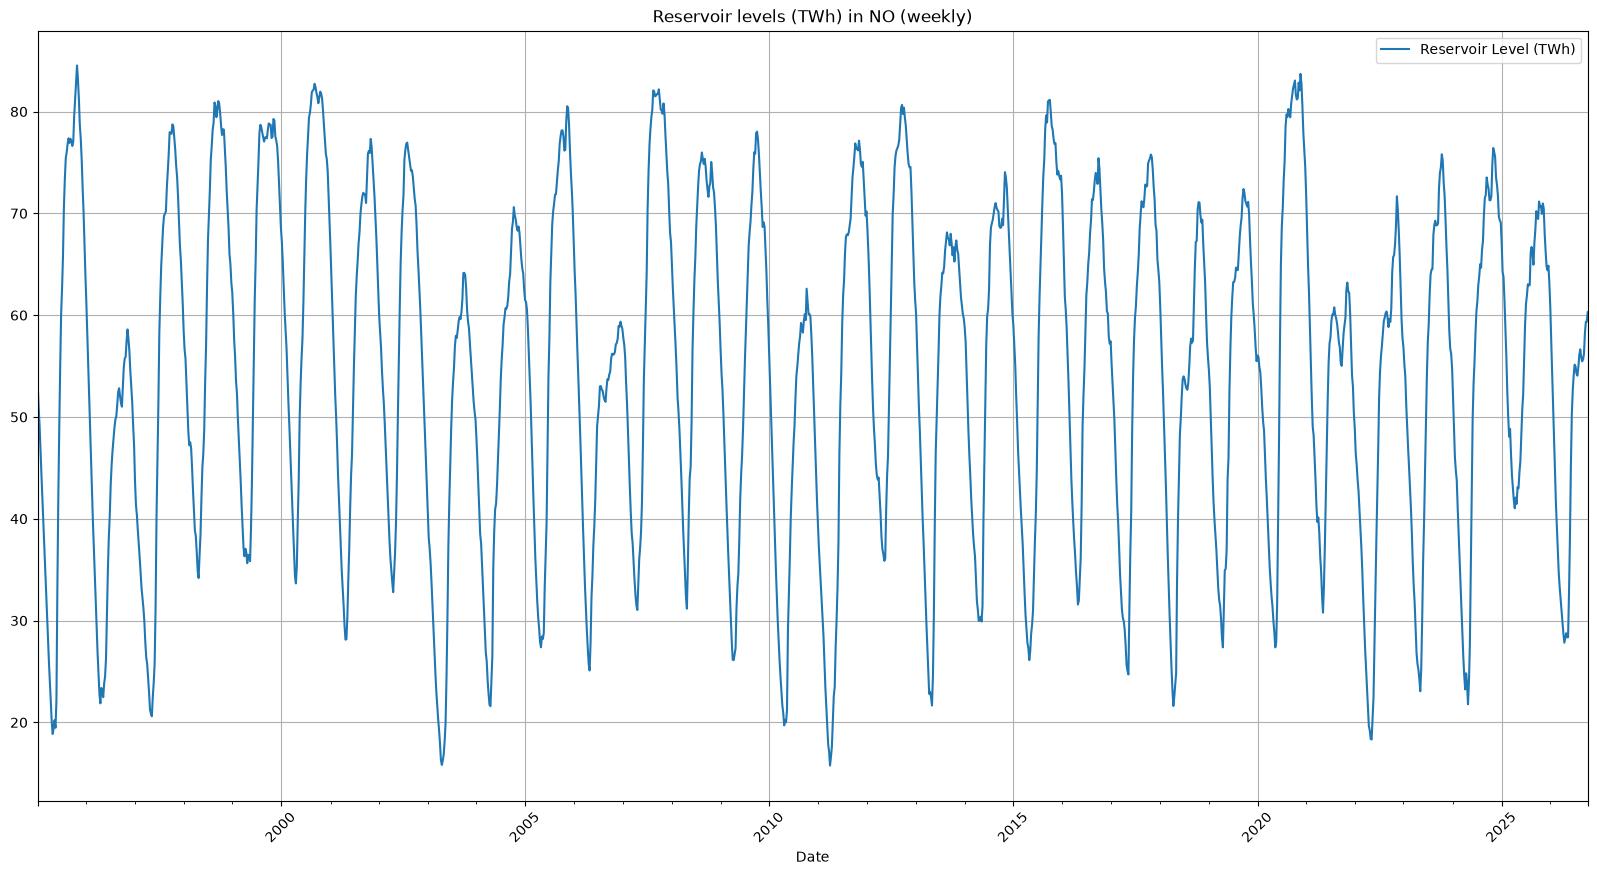

In [4]:
# Creating a subset of the dataframe for area_type NO
subset_2 = df[df['area_type'] == 'NO'] 

# Plotting the reservoirs levels in TWh in area_type NO over time with instructions for figure size, title, x- and y-labels, and legend
ax2 = subset_2.plot(x='Date', 
              y='res_level_TWh',
              kind='line', 
              title='Reservoir levels (TWh) in NO (weekly)', 
              figsize=(20,10),
              rot=45, 
              grid=True)

ax2.legend(["Reservoir Level (TWh)"])
# Making sure the plot is displayed
plt.show()

### Reservoir levels in area type EL (Area nr. 1-5)

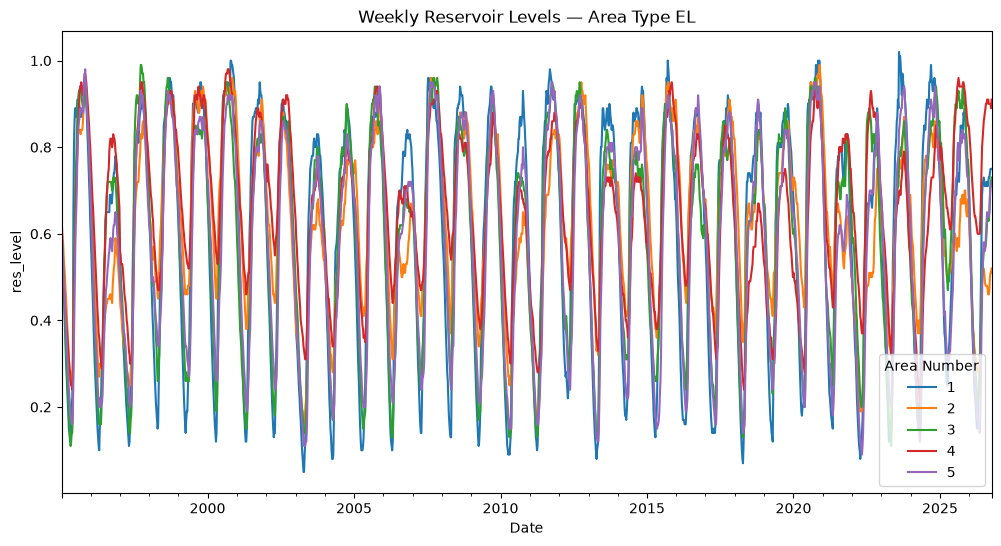

In [5]:
# Plotting the reservoir levels in area_type EL area_nr 1-5 over time

# Creating a subset of the dataframe for area_type EL
el = df[df['area_type'] == 'EL'] 

# Creating a pivot table with Date as index, area_nr as columns, and res_level as values
pivoted = el.pivot_table(index='Date', columns='area_nr', values='res_level') 

# Plotting the pivoted dataframe with instructions for figure size, title, x- and y-labels, and legend
pivoted.plot(figsize=(12, 6))
plt.title('Weekly Reservoir Levels — Area Type EL')
plt.xlabel('Date')
plt.ylabel('res_level')
plt.legend(title='Area Number',loc='lower right')

# Making sure the plot is displayed
plt.show()

### Change in reservoir levels in area type NO

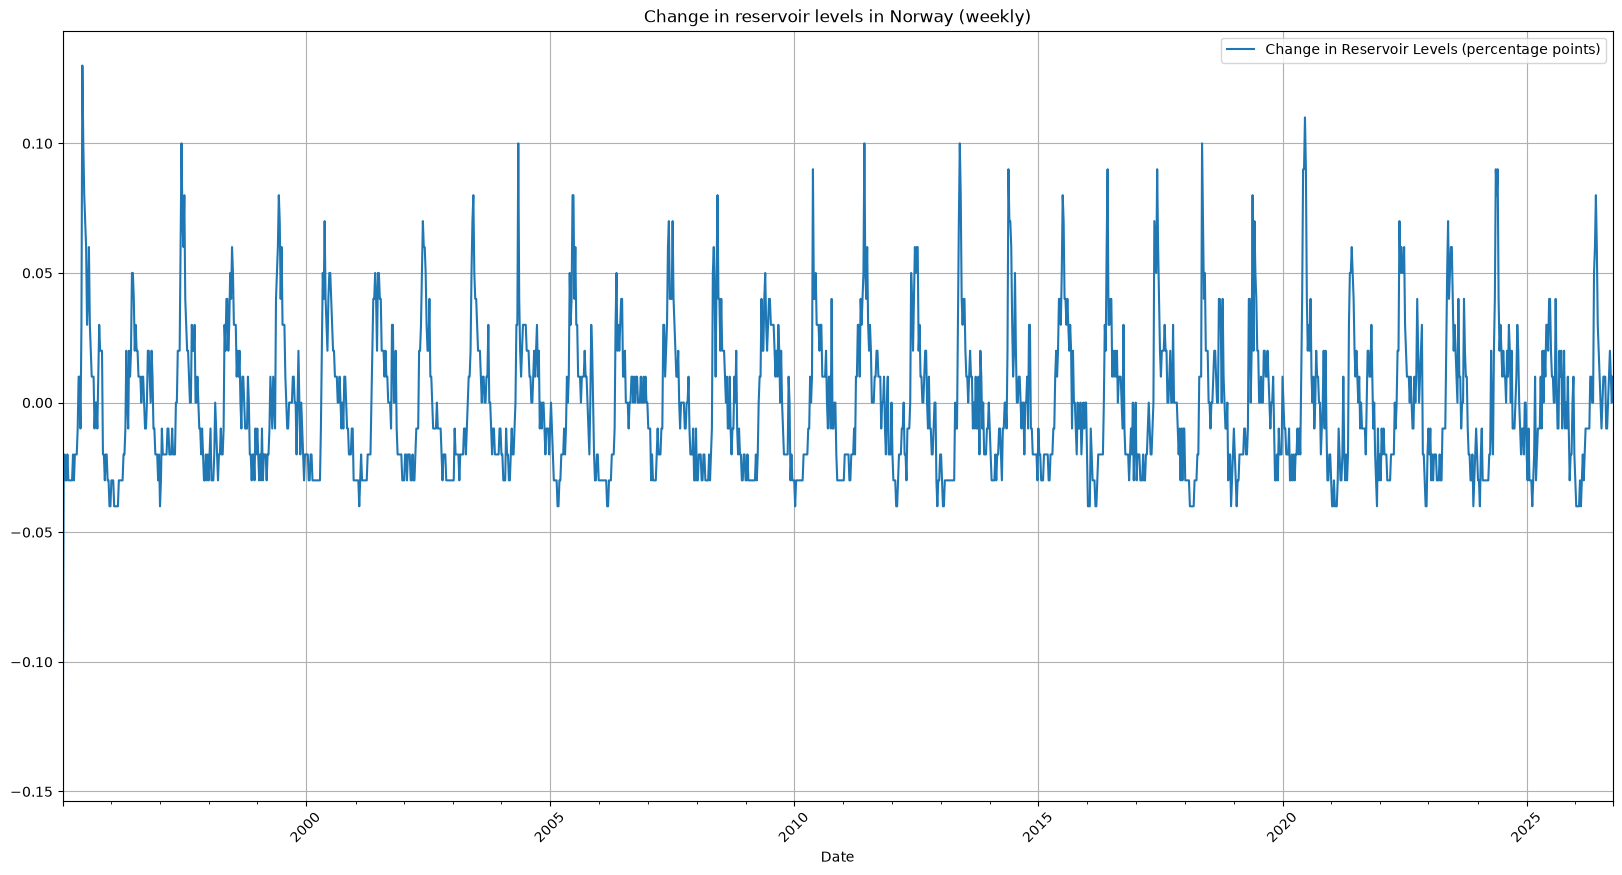

In [6]:
# Plotting the change in reservoir levels in area_type NO over time
subset_3 = df[df['area_type'] == 'NO'] # Creating a subset of the dataframe for area_type NO

# Plotting the change in reservoir levels in area_type NO over time with instructions for figure size, title, x- and y-labels, and legend
ax3 = subset_3.plot(x='Date', 
              y='change_res_level',
              kind='line', 
              title='Change in reservoir levels in Norway (weekly)', 
              figsize=(20,10),
              rot=45, 
              grid=True)

# Renaming the legend to be easier to understand
ax3.legend(['Change in Reservoir Levels (percentage points)'])
# Making sure the plot is displayed
plt.show()

### Previous Reservoir Levels for area type NO

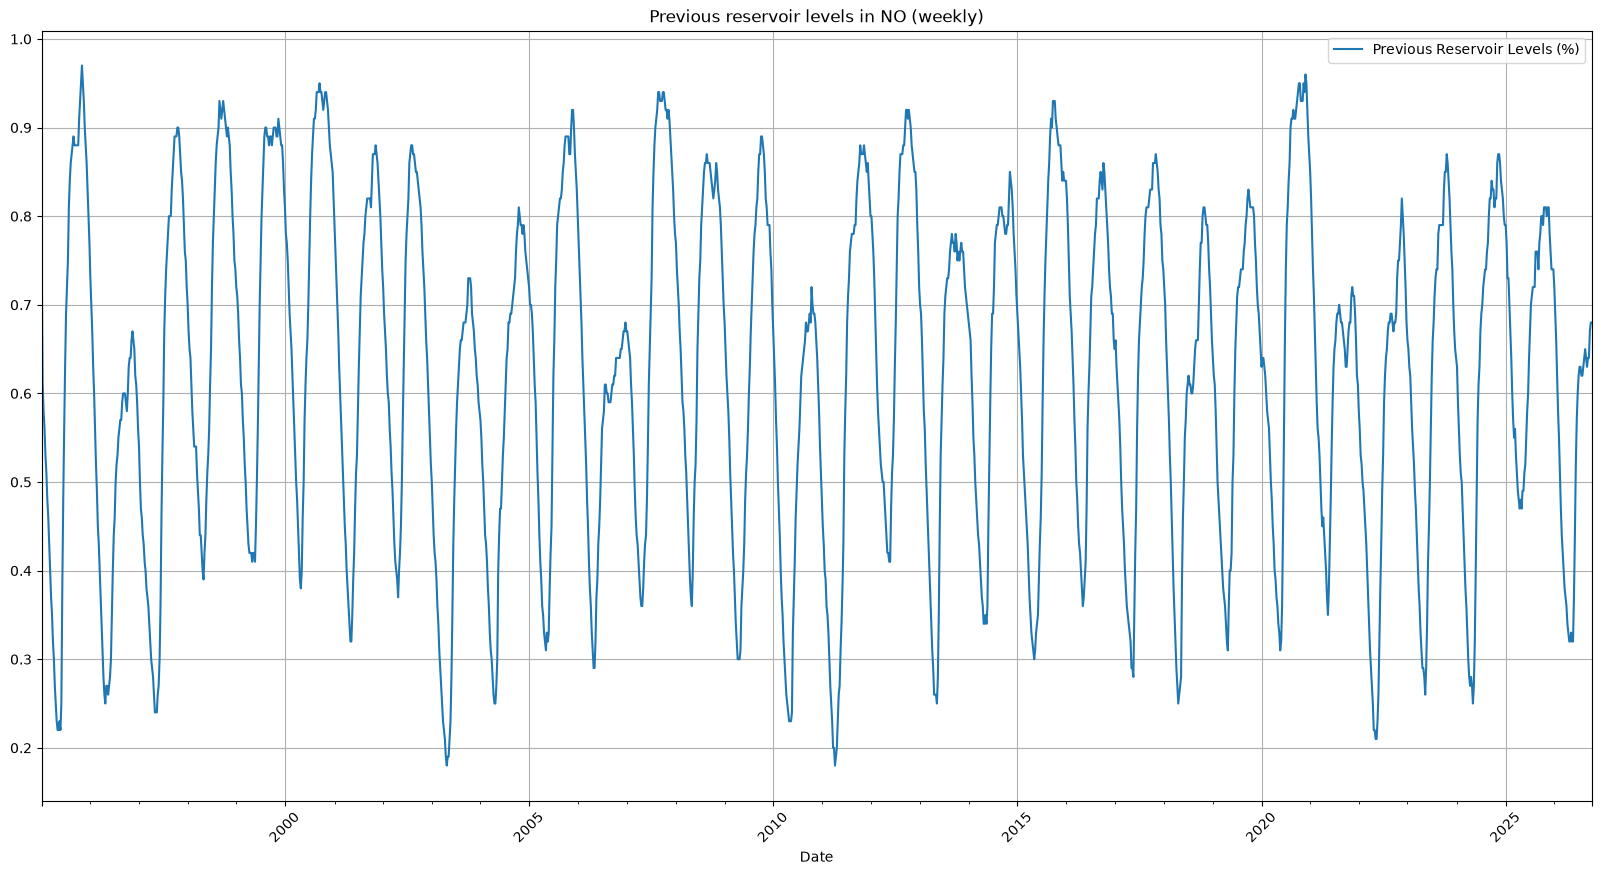

In [7]:
# Plotting the reservoir levels in NO over time

# Creating a subset of the dataframe for previous reservoir levels in area_type NO over time
subset_4 = df[df['area_type'] == 'NO'] 

# Creating an Axes object plotting the previous reservoir levels in area_type NO over time 
# with instructions for figure size, title, grid, x- and y-labels (rotation for x-labels), and legend
ax4 = subset_4.plot(x = 'Date', 
              y = 'prev_res_level', 
              kind = 'line', 
              title = 'Previous reservoir levels in NO (weekly)', 
              figsize = (20,10),
              rot = 45, 
              grid = True,
              legend=True)

# Renaming the legend
ax4.legend(['Previous Reservoir Levels (%)'])

# Making sure the plot is displayed
plt.show()

### Plotting all columns together (NO)

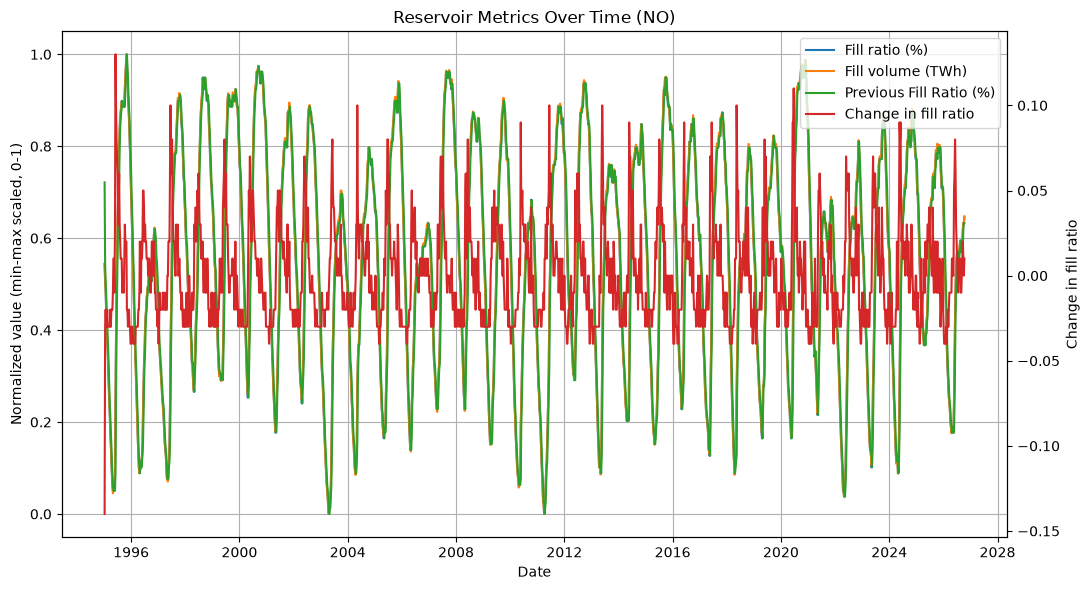

In [8]:
# The code for filtering and then plotting

# Redefining the dataframe to be a subset for only area type 'NO'
df = df[df["area_type"] == 'NO']

# Raises an error if no rows are left after the filter (should work if everything earlier in the notebook works)
if df.empty:
    raise ValueError(f"No rows found for area_type == {'NO'}")

# Selecting columns to plot
plot_cols = ['res_level', 'res_level_TWh', 'prev_res_level', 'change_res_level']

# Adding a dictionary to change the labels for the legends in the plots
legend_labels = {
    "res_level": "Fill ratio (%)",
    "res_level_TWh": "Fill volume (TWh)",
    "prev_res_level": "Previous Fill Ratio (%)",
    "change_res_level": "Change in fill ratio",
}

# Split into "left axis" columns (everything except the change column)
# and the change column going on the right axis
left_cols = [c for c in plot_cols if c != "change_res_level"]
right_col = "change_res_level"

# Normalizing each column going in the "left side" of the plot independently
df_norm = df.copy()
for col in left_cols:
    col_min = df[col].min()
    col_max = df[col].max()
    span = col_max - col_min
    df_norm[col] = 0.0 if span == 0 else (df[col] - col_min) / span

# Creating the figure and subplot ax1 for left_cols
fig, ax1 = plt.subplots(figsize=(11, 6))

# Left axis: everything except change in reservoir levels
for col in left_cols:
    label = legend_labels.get(col, col)
    ax1.plot(df["Date"], 
             df_norm[col], 
             label=label)

# Setting the labels for subplot 1 and adding a grid
ax1.set_xlabel("Date")
ax1.set_ylabel("Normalized value (min-max scaled, 0-1)")
ax1.grid(True)

# Right axis: Change in Fill Ratio
ax2 = ax1.twinx()
ax2.plot(df["Date"], 
         df[right_col],
          color="tab:red", 
          label=legend_labels.get(right_col, right_col))

# Setting the label for the y-axis for the subplot with axis on the right side (change in fill ratio)
ax2.set_ylabel("Change in fill ratio")

# Combining legend from both axes and setting the locating to the upper right of the plot
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper right")

# Setting the title of the plot
ax1.set_title("Reservoir Metrics Over Time (NO)")

# Makes sure labels don't overlap
fig.tight_layout()

# Making sure the plots are shown
plt.show()

## ENTSO-E API

### Cassandra

In [1]:
# Importing cluster from cassandra library and creating a connection to the cassandra databse running on localhost med port 9042
from cassandra.cluster import Cluster
cluster = Cluster(['Localhost'], port = 9042)
session = cluster.connect()

# Lager keyspace ind320 hvis den ikke finnes
session.execute("""
    CREATE KEYSPACE IF NOT EXISTS ind320
    WITH REPLICATION = {'class': 'SimpleStrategy', 'replication_factor': 1};
""")

#Bruker keyspace ind320
session.set_keyspace('ind320')

In [2]:
import os, sys, pyspark
os.environ["JAVA_HOME"] = r"C:\Program Files\Microsoft\jdk-17.0.20.101-hotspot"
os.environ["SPARK_HOME"] = os.path.dirname(pyspark.__file__)
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["PYSPARK_HADOOP_VERSION"] = "without"
os.environ["TEMP"] = r"C:\tmp"
os.environ["TMP"] = r"C:\tmp"
os.environ["HADOOP_HOME"] = r"C:\hadoop"
os.environ["PATH"] = r"C:\hadoop\bin;" + os.environ["PATH"]
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"  # Spark og Python-prosessene kommuniserer lokalt

# print(os.environ["JAVA_HOME"])
# print(os.path.exists(os.path.join(os.environ["JAVA_HOME"], "bin", "java.exe")))
# print(os.environ.get("HADOOP_HOME"))
# print(os.path.exists(r"C:\hadoop\bin\winutils.exe"))
# print(os.path.getsize(r"C:\hadoop\bin\winutils.exe") if os.path.exists(r"C:\hadoop\bin\winutils.exe") else "mangler")


In [3]:
from pyspark.sql import SparkSession
spark = SparkSession.builder.appName('IND320').\
    config('spark.jars.packages', 'com.datastax.spark:spark-cassandra-connector_2.12:3.5.1').\
    config('spark.cassandra.connection.host', 'localhost').\
    config('spark.sql.extensions', 'com.datastax.spark.connector.CassandraSparkExtensions').\
    config('spark.sql.catalog.mycatalog', 'com.datastax.spark.connector.datasource.CassandraCatalog').\
    config('spark.cassandra.connection.port', '9042').\
    config('spark.driver.host', '127.0.0.1').\
    config('spark.sql.execution.arrow.pyspark.enabled', 'true').\
    getOrCreate()

spark.sql("SHOW NAMESPACES FROM mycatalog").show()

+---------+
|namespace|
+---------+
|   ind320|
+---------+



#### Downloading the data from ENTSO-E

In [4]:
# Henter fysisk grenseflyt (documentType A11) fra ENTSO-E for alle norske
# utenlandsforbindelser, begge retninger, de to siste årene.
# ENTSO-E gir maks ett år per kall, så hvert år hentes for seg.
import requests
import pandas as pd
import xml.etree.ElementTree as ET
from pathlib import Path

no_sync = Path("../no_sync")
URL_ENTSO_E = "https://web-api.tp.entsoe.eu/api"
API_KEY = (no_sync / "entsoe_token.txt").read_text().strip()

# EIC-koder for budområdene
EIC = {
    "NO1": "10YNO-1--------2", "NO2": "10YNO-2--------T", "NO3": "10YNO-3--------J",
    "NO4": "10YNO-4--------9", "SE1": "10Y1001A1001A44P", "SE2": "10Y1001A1001A45N",
    "SE3": "10Y1001A1001A46L", "FI": "10YFI-1--------U", "DK1": "10YDK-1--------W",
    "NL": "10YNL----------L", "DE": "10Y1001A1001A82H", "GB": "10YGB----------A",
}
FORBINDELSER = [("NO1", "SE3"), ("NO3", "SE2"), ("NO4", "SE1"), ("NO4", "SE2"),
                ("NO4", "FI"), ("NO2", "DK1"), ("NO2", "NL"), ("NO2", "DE"), ("NO2", "GB")]
PERIODER = [("202410160000", "202510160000"), ("202510160000", "202610160000")]


def hent_flyt(fra, til, start, slutt):
    """Henter flyt fra område 'fra' til 'til' og gjør XML-svaret om til en DataFrame."""
    params = {"securityToken": API_KEY, "documentType": "A11",
              "out_Domain": EIC[fra], "in_Domain": EIC[til],
              "periodStart": start, "periodEnd": slutt}
    r = requests.get(URL_ENTSO_E, params=params, timeout=60)
    root = ET.fromstring(r.content)

    rows = []
    for period in root.iterfind(".//{*}Period"):
        p_start = pd.Timestamp(period.find("{*}timeInterval/{*}start").text)
        p_end = pd.Timestamp(period.find("{*}timeInterval/{*}end").text)
        step = pd.Timedelta(minutes=15 if period.find("{*}resolution").text == "PT15M" else 60)
        points = {int(p.find("{*}position").text): float(p.find("{*}quantity").text)
          for p in period.iterfind("{*}Point")}
        verdi = None
        for pos in range(1, int((p_end - p_start) / step) + 1):
            verdi = points.get(pos, verdi)  # curveType A03: verdien gjelder til neste punkt
            rows.append({"time": p_start + step * (pos - 1), "mw": verdi})

    if not rows:
        print(f"Ingen data for {fra}->{til} {start}: status {r.status_code}")
    return pd.DataFrame(rows, columns=["time", "mw"])


deler = []
for no, utland in FORBINDELSER:
    for start, slutt in PERIODER:
        for fra, til, retning in [(no, utland, "export"), (utland, no, "import")]:
            d = hent_flyt(fra, til, start, slutt)
            d["connection"] = f"{no}-{utland}"
            d["direction"] = retning
            deler.append(d)

df_flyt = pd.concat(deler, ignore_index=True)

In [5]:
df_flyt["time"] = pd.to_datetime(df_flyt["time"], utc=True).dt.tz_localize(None)  # UTC without time zone for Spark/Cassandra
df_flyt["time"] = df_flyt["time"].dt.floor("h")
df_flyt = (df_flyt.groupby(["connection", "direction", "time"], as_index=False)["mw"]
                  .mean())

print(df_flyt["mw"].isna().sum())  # bør være 0
df_flyt.groupby(["connection", "direction"]).size()

0


connection  direction
NO1-SE3     export       17520
            import       17520
NO2-DE      export       17520
            import       17520
NO2-DK1     export       17520
            import       17520
NO2-GB      export       17520
            import       17520
NO2-NL      export       17520
            import       17520
NO3-SE2     export       17520
            import       17520
NO4-FI      export       17520
            import       17520
NO4-SE1     export       17520
            import       17520
NO4-SE2     export       17520
            import       17520
dtype: int64

In [14]:
print(response.status_code)
print(response.text)

200
[{"dato_Id":"1995-09-03","omrType":"EL","omrnr":4,"iso_aar":1995,"iso_uke":35,"fyllingsgrad":0.94472134,"kapasitet_TWh":21.079208,"fylling_TWh":19.913979,"neste_Publiseringsdato":"0001-01-01T00:00:00","fyllingsgrad_forrige_uke":0.9368882,"endring_fyllingsgrad":0.007833123},{"dato_Id":"2020-11-15","omrType":"EL","omrnr":1,"iso_aar":2020,"iso_uke":46,"fyllingsgrad":0.97436064,"kapasitet_TWh":6.0032635,"fylling_TWh":5.849344,"neste_Publiseringsdato":"2020-11-25T13:00:00","fyllingsgrad_forrige_uke":0.99740624,"endring_fyllingsgrad":-0.0230456},{"dato_Id":"2011-08-28","omrType":"EL","omrnr":4,"iso_aar":2011,"iso_uke":34,"fyllingsgrad":0.7864988,"kapasitet_TWh":21.079208,"fylling_TWh":16.578772,"neste_Publiseringsdato":"0001-01-01T00:00:00","fyllingsgrad_forrige_uke":0.7871927,"endring_fyllingsgrad":-0.0006939173},{"dato_Id":"1998-07-05","omrType":"EL","omrnr":3,"iso_aar":1998,"iso_uke":27,"fyllingsgrad":0.7939694,"kapasitet_TWh":8.920932,"fylling_TWh":7.082947,"neste_Publiseringsdato":"

In [6]:
# Lager tabellen for grenseflyt i Cassandra via Spark-katalogen
spark.sql("""
    CREATE TABLE IF NOT EXISTS mycatalog.ind320.crossborder_flow (
        connection STRING,
        direction STRING,
        time TIMESTAMP,
        mw DOUBLE
    )
    USING cassandra
    PARTITIONED BY (connection, direction)
    TBLPROPERTIES (clustering_key = 'time.asc')
""")

spark.sql("SHOW TABLES IN mycatalog.ind320").show()


# Skriver grenseflyt-dataene (timesoppløsning) til Cassandra med Spark
sdf = spark.createDataFrame(df_flyt[["connection", "direction", "time", "mw"]])
(sdf.write
    .format("org.apache.spark.sql.cassandra")
    .options(keyspace="ind320", table="crossborder_flow")
    .mode("append")
    .save())

# Kontroll: les tilbake fra Cassandra og tell rader per forbindelse og retning
sdf_check = (spark.read.format("org.apache.spark.sql.cassandra")
             .options(keyspace="ind320", table="crossborder_flow")
             .load())
sdf_check.groupBy("connection", "direction").count().orderBy("connection", "direction").show(20)

+---------+----------------+-----------+
|namespace|       tableName|isTemporary|
+---------+----------------+-----------+
|   ind320|crossborder_flow|      false|
+---------+----------------+-----------+



c:\venvs\ind320\Lib\site-packages\pyspark\sql\pandas\conversion.py:351: UserWarning: createDataFrame attempted Arrow optimization because 'spark.sql.execution.arrow.pyspark.enabled' is set to true; however, failed by the reason below:
  2025-03-30 02:00:00 is a nonexistent time due to daylight savings time. Try using the 'nonexistent' argument.
Attempting non-optimization as 'spark.sql.execution.arrow.pyspark.fallback.enabled' is set to true.
  warn(msg)


+----------+---------+-----+
|connection|direction|count|
+----------+---------+-----+
|   NO1-SE3|   export|17518|
|   NO1-SE3|   import|17518|
|    NO2-DE|   export|17518|
|    NO2-DE|   import|17518|
|   NO2-DK1|   export|17518|
|   NO2-DK1|   import|17518|
|    NO2-GB|   export|17518|
|    NO2-GB|   import|17518|
|    NO2-NL|   export|17518|
|    NO2-NL|   import|17518|
|   NO3-SE2|   export|17518|
|   NO3-SE2|   import|17518|
|    NO4-FI|   export|17518|
|    NO4-FI|   import|17518|
|   NO4-SE1|   export|17518|
|   NO4-SE1|   import|17518|
|   NO4-SE2|   export|17518|
|   NO4-SE2|   import|17518|
+----------+---------+-----+



In [7]:
# Viser hvilke tabeller som finnes i keyspacet ind320
rows = session.execute(
    "SELECT table_name FROM system_schema.tables WHERE keyspace_name = 'ind320'"
)
print([r.table_name for r in rows])

['crossborder_flow']


In [11]:
from pyspark.sql import functions as F

# Read from Cassandra and pick the relevant columns
sdf_flyt = (spark.read.format("org.apache.spark.sql.cassandra")
            .options(keyspace="ind320", table="crossborder_flow")
            .load()
            .select("connection", "direction", "time", "mw"))

# Choose a connection. This filter is on the partition key, so it is pushed down to Cassandra
chosen_connection = "NO2-DE"
sdf_chosen = sdf_flyt.filter(F.col("connection") == valgt)

# To pandas, converted to Norwegian time before grouping by year and month
pdf = sdf_chosen.toPandas()
pdf["time"] = pdf["time"].dt.tz_localize("UTC").dt.tz_convert("Europe/Oslo")
pdf["year"] = pdf["time"].dt.year
pdf["month"] = pdf["time"].dt.month

# Pie chart: total in and out of Norway for one year
pie_df = pdf[pdf["year"] == 2025].groupby("direction")["mw"].sum()

# Line plot: first month of the year, one line per direction
line_df = pdf[(pdf["year"] == 2025) & (pdf["month"] == 1)]

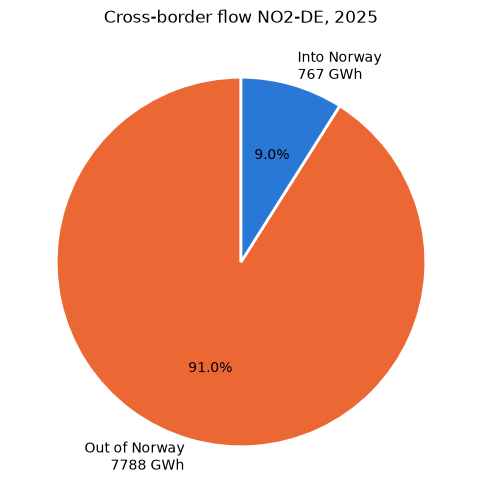

In [ ]:
import matplotlib.pyplot as plt

år = 2025   # first full calendar year in the data (2024 and 2026 are only partly covered)
FARGER = {"import": "#2a78d6", "export": "#eb6834"}   # same colour per direction in both plots
ETIKETT = {"import": "Into Norway", "export": "Out of Norway"}

# --- Pie chart: total in and out of Norway for one year ---
# Hourly MW summed over the year = MWh. Divided by 1000 to get GWh
pie_gwh = pie_df / 1000

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    pie_gwh.values,
    labels=[f"{ETIKETT[d]}\n{v:.0f} GWh" for d, v in pie_gwh.items()],
    colors=[FARGER[d] for d in pie_gwh.index],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white", "linewidth": 2},
)
ax.set_title(f"Cross-border flow {chosen_connection}, {år}")
plt.show()

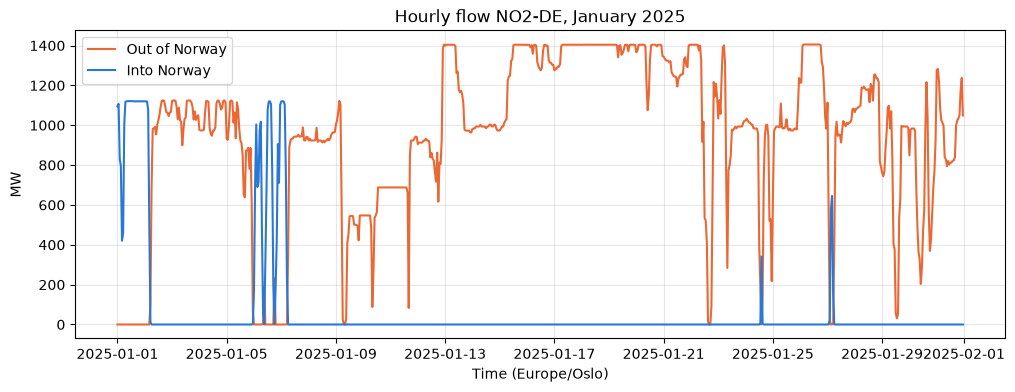

In [13]:
# --- Line plot: first month of the year, one line per direction ---
fig, ax = plt.subplots(figsize=(12, 4))
for retning, gruppe in line_df.groupby("direction"):
    ax.plot(gruppe["time"], gruppe["mw"], label=ETIKETT[retning],
            color=FARGER[retning], linewidth=1.5)

ax.set_title(f"Hourly flow {chosen_connection}, January {år}")
ax.set_xlabel("Time (Europe/Oslo)")
ax.set_ylabel("MW")
ax.grid(alpha=0.3)
ax.legend()
plt.show()

In [19]:
from pymongo import MongoClient

MONGO_URI = (no_sync / "mongodb_uri.txt").read_text().strip()

client = MongoClient(MONGO_URI)

try:
    client.admin.command('ping')
    print("Pinged your deployment. You successfully connected to MongoDB!")
except Exception as e:
    print(e)

Pinged your deployment. You successfully connected to MongoDB!


In [21]:
# Testing basic operations on a separate test collection
test = client["ind320"]["test"]
test.insert_one({"name": "test", "value": 1})                       # Create
print(test.find_one({"name": "test"}))                              # Read
test.update_one({"name": "test"}, {"$set": {"value": 2}})           # Update
print(test.find_one({"name": "test"}))
test.delete_one({"name": "test"})                                   # Delete
client["ind320"].drop_collection("test");                           # Clean up

{'_id': ObjectId('6ad36f543e5b83aa0e9f8d2c'), 'name': 'test', 'value': 1}
{'_id': ObjectId('6ad36f543e5b83aa0e9f8d2c'), 'name': 'test', 'value': 2}


In [ ]:
coll = client["ind320"]["crossborder_flow"]

# Data extracted from Cassandra with Spark (all connections, hourly values in UTC)
pdf_alle = sdf_flyt.toPandas()

coll.delete_many({})                                     # avoid duplicates if the cell is run again
coll.insert_many(pdf_alle.to_dict("records"))
coll.create_index([("connection", 1), ("time", 1)])     # fast lookups from Streamlit

print(coll.count_documents({}), "documents in MongoDB")

315324 documents in MongoDB


----------------------------------------
Exception occurred during processing of request from ('127.0.0.1', 55480)
Traceback (most recent call last):
  File "C:\Users\Magnus Frantsen\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 317, in _handle_request_noblock
    self.process_request(request, client_address)
  File "C:\Users\Magnus Frantsen\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 348, in process_request
    self.finish_request(request, client_address)
  File "C:\Users\Magnus Frantsen\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 361, in finish_request
    self.RequestHandlerClass(request, client_address, self)
  File "C:\Users\Magnus Frantsen\AppData\Local\Programs\Python\Python311\Lib\socketserver.py", line 755, in __init__
    self.handle()
  File "c:\venvs\ind320\Lib\site-packages\pyspark\accumulators.py", line 295, in handle
    poll(accum_updates)
  File "c:\venvs\ind320\Lib\site-packages\pyspark\accumulators.py